<a href="https://colab.research.google.com/github/faiq191/244107020214-machine-learning/blob/main/JS10/JS10_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
	import numpy as np
	import matplotlib.pyplot as plt
	import pandas as pd
	import seaborn as sns

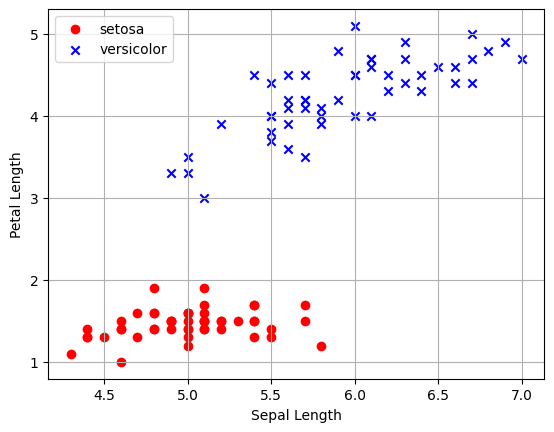

In [29]:
df = pd.read_csv('/content/Iris.csv', header=None, skiprows=1)
setosa = df[df[5] == 'Iris-setosa']
versicolor = df[df[5] == 'Iris-versicolor']
virginica = df[df[5] == 'Iris-virginica']

a, b = 1, 3
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')
plt.legend(loc='upper left')
plt.grid()
plt.show()

In [31]:
y = df.iloc[0:100, 5].values # select species (column index 5) for the first 100 data points
y = np.where(y == 'Iris-setosa', -1, 1) # change label encoding
X = df.iloc[0:100, [1, 3]].values # slice training features (Sepal Length index 1, Petal Length index 3)

In [32]:
	ppn = Perceptron(eta=0.1, n_iter=10)
	ppn.fit(X, y)

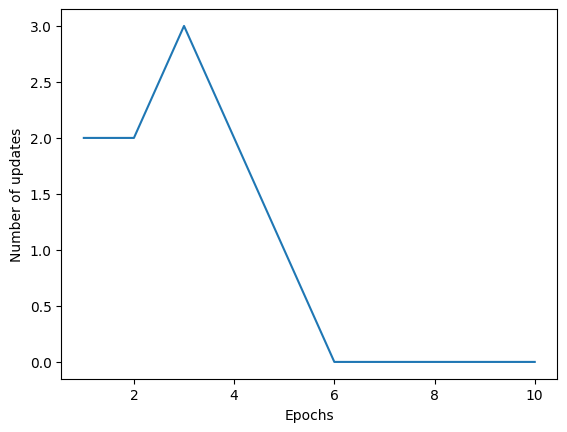

In [33]:
	plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
	plt.xlabel('Epochs')
	plt.ylabel('Number of updates')
	plt.show()

In [41]:
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=[cmap(i)], marker=markers[i], label=cl)

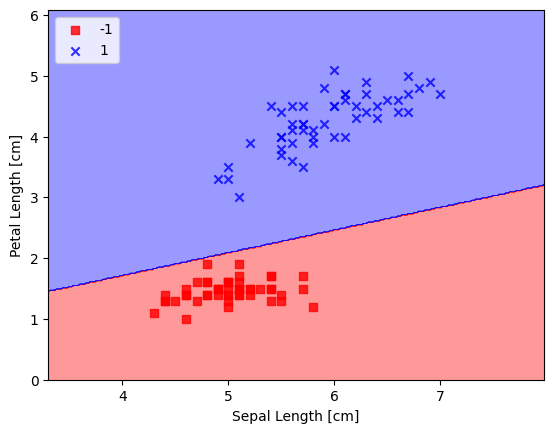

In [39]:
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('Sepal Length [cm]')
plt.ylabel('Petal Length [cm]')
plt.legend(loc='upper left')
plt.show()